In [1]:
import matplotlib.pyplot as plt

# An introduction to data generation

Data generation schemes in TabICL (strongly influenced by those of TabPFN) are based on tree-like MLPs and boosted trees.

Meanwhile, data geration in TimePFN is based on Gaussian Processes. Although these could be interpreted as generalized by trees (and MLPs) wih more general binary operations, we implement that scheme as well to enable comparing both approaches.

# TabICL : SCM-based

In [2]:
from lmetk.synthetic_data.tabicl_style.mlp_scm import MLPSCM
from lmetk.synthetic_data.tabicl_style.tree_scm import TreeSCM
from lmetk.synthetic_data.tabicl_style.activations import SineActivation

## Sigmoid-Based Net with non-time-like causes

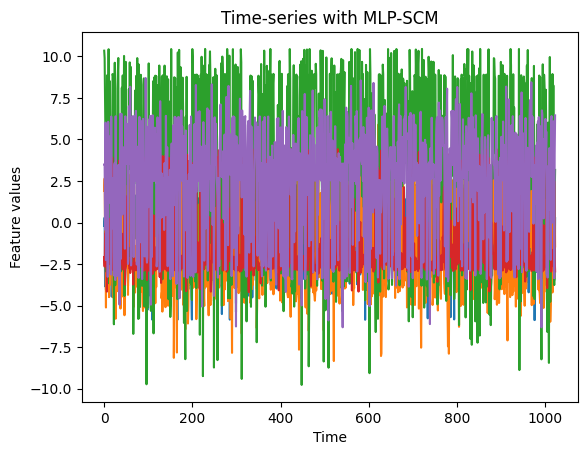

In [ ]:
# Define an MLP-based SCM
num_causes = 2 # Number of base (input) nodes to the tree.
sampling = "uniform" # Picks the causes randomly from a uniform distribution
noise_std = 0.001 # Standard deviation of the noise added at each layer
mlp_scm = MLPSCM(num_causes=2,num_outputs=1,sampling=sampling,num_features=5,noise_std=noise_std, num_layers=10)
# Visualize the output 
x, y = mlp_scm()
plt.plot(x[:,:].detach().numpy())
plt.xlabel("Time")
plt.ylabel("Feature values")
plt.title("Time-series with MLP-SCM")
plt.show()

## Sigmoid-Based Net with simple time-like cause

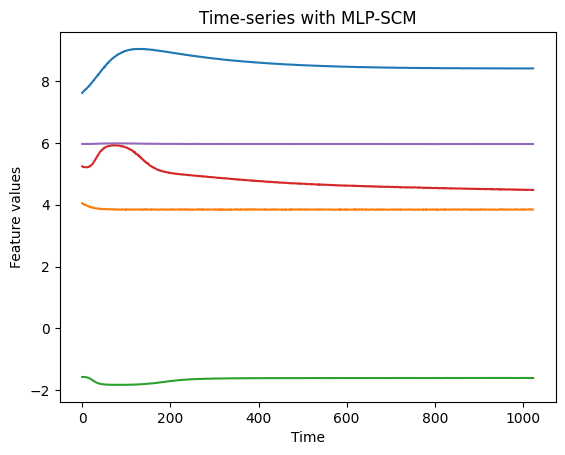

In [3]:
# Define an MLP-based SCM
num_causes = 2 # Number of base (input) nodes to the tree. We use two here due to implementation details
sampling = "time" # Makes the causes increase monotonically in time
noise_std = 0.001 # Standard deviation of the noise added at each layer
mlp_scm = MLPSCM(num_causes=2,num_outputs=1,sampling=sampling,num_features=5,noise_std=noise_std, num_layers=10)
# Visualize the output 
x, y = mlp_scm()
plt.plot(x[:,:].detach().numpy())
plt.xlabel("Time")
plt.ylabel("Feature values")
plt.title("Time-series with MLP-SCM")
plt.show()

## Sinusoid-Based Net with multi-scale time-like causes

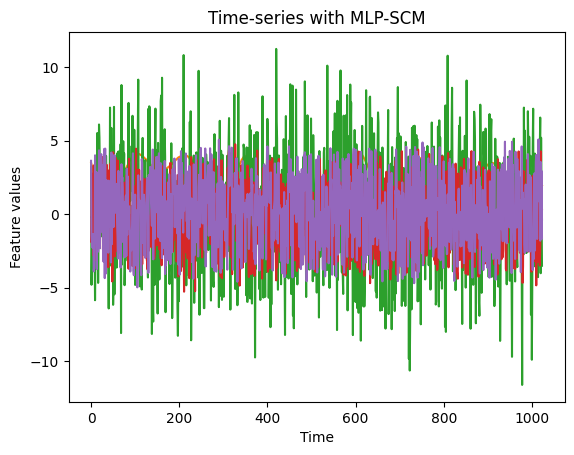

In [14]:
# Define a MLP-based SCM with 4 time scales and sinusoidal activation.
num_causes = 2 # Number of base (input) nodes to the tree
sampling = "time_multiscale" # Makes the causes increase monotonically with multiple time scales
noise_std = 0.001 # Standard deviation of the noise added at each level the output
activation = SineActivation
mlp_scm = MLPSCM(num_causes=4,num_outputs=1,sampling=sampling,num_features=5,noise_std=noise_std, mlp_activations=activation,num_layers=10)

# Visualize the output 
x, y = mlp_scm()
plt.plot(x[:,:].detach().numpy())
plt.xlabel("Time")
plt.ylabel("Feature values")
plt.title("Time-series with MLP-SCM")
plt.show()

## Sinusoid-Based Net with single time-like cause and normally distributed external input

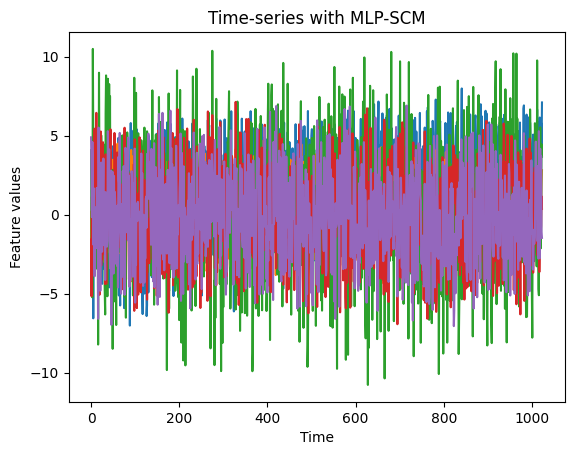

In [ ]:
# Define a MLP-based SCM with 1 time scale and external inputs
num_causes = 2 # Number of base (input) nodes to the tree
sampling = "time_and_normal" 
noise_std = 0.000 # Standard deviation of the noise added at each level the output
activation = SineActivation
mlp_scm = MLPSCM(num_causes=4,num_outputs=1,sampling=sampling,num_features=5,noise_std=noise_std, mlp_activations=activation,num_layers=10)

# Visualize the output 
x, y = mlp_scm()
plt.plot(x[:,:].detach().numpy())
plt.xlabel("Time")
plt.ylabel("Feature values")
plt.title("Time-series with MLP-SCM")
plt.show()

## Boosted Tree with single time-like cause

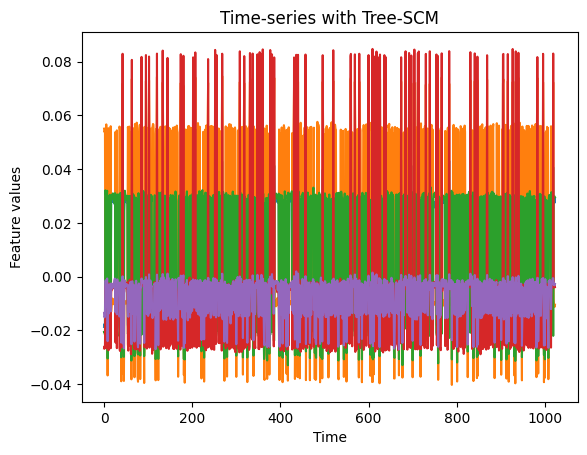

In [10]:
# This fails randomly, might need to run cell multiple times
# Define a MLP-based SCM with 4 time scales and sinusoidal activation.
num_causes = 2 # Number of base (input) nodes to the tree
sampling = "time_multiscale" # Makes the causes increase monotonically with multiple time scales
noise_std = 0.001 # Standard deviation of the noise added at each level the output
tree_scm = TreeSCM(noise_std=noise_std,num_features=5)

# Visualize the output 
x, y = tree_scm()
plt.plot(x[:,:].detach().numpy())
plt.xlabel("Time")
plt.ylabel("Feature values")
plt.title("Time-series with Tree-SCM")
plt.show()

# TimePFN: GP-based

In [11]:
from lmetk.synthetic_data.timepfn_style.LMC_Synth import generate_time_series as LMC_generate_time_series

/opt/anaconda3/envs/tabphm/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


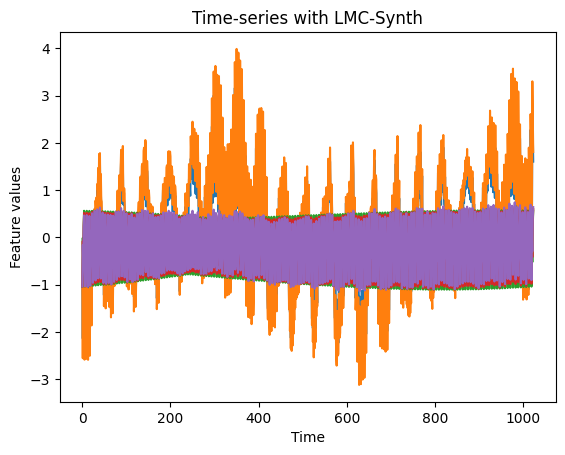

In [12]:
# Set paraters for the associated Weibull distribution
dirichlet_min = 0.1
dirichlet_max = 1.1
scale = 1.0
weibull_shape = 1.0
weibull_scale = 1 # We keep the typo from TimePFN to avoid changing the code too much
max_kernels = 5
num_channels = 5
series = LMC_generate_time_series(
    dirichlet_min=dirichlet_min,
    dirichlet_max=dirichlet_max,
    scale=scale,
    weibull_shape=weibull_shape,
    weibul_scale=weibull_scale,
    max_kernels=max_kernels,
    num_channels=num_channels,)

plt.plot(series['target'].T)
plt.xlabel("Time")
plt.ylabel("Feature values")
plt.title("Time-series with LMC-Synth")
plt.show()

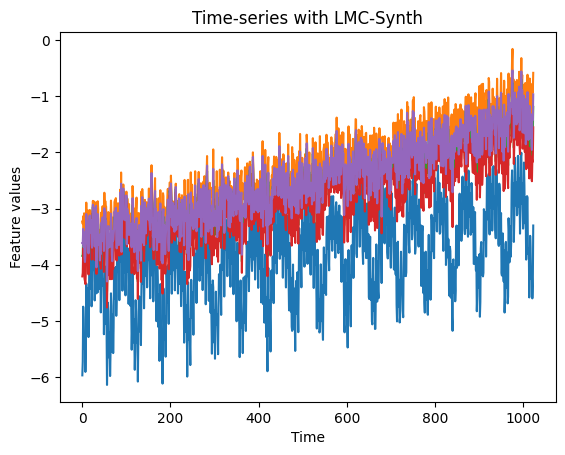

In [13]:
# Generate again with the exact same paraters and obtain something completely different
series = LMC_generate_time_series(
    dirichlet_min=dirichlet_min,
    dirichlet_max=dirichlet_max,
    scale=scale,
    weibull_shape=weibull_shape,
    weibul_scale=weibull_scale,
    max_kernels=max_kernels,
    num_channels=num_channels,)

plt.plot(series['target'].T)
plt.xlabel("Time")
plt.ylabel("Feature values")
plt.title("Time-series with LMC-Synth")
plt.show()